In [1]:
"""
Toxic Comment Classification using LSTM (simple version)
Dataset: Jigsaw Toxic Comment Classification (Kaggle) -> train.csv in the same folder
"""

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, classification_report
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

LABELS = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]
MAX_WORDS = 20000
MAX_LEN = 150


In [2]:
# 1. Load and clean data
df = pd.read_csv("train.csv")

def clean(text):
    text = text.lower()
    text = re.sub(r"http\S+", " ", text)
    text = re.sub(r"[^a-z0-9'!?\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

df["text"] = df["comment_text"].astype(str).apply(clean)

df.head()


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,text
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,explanation why the edits made under my userna...
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,d'aww! he matches this background colour i'm s...
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,hey man i'm really not trying to edit war it's...
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,more i can't make any real suggestions on impr...
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,you sir are my hero any chance you remember wh...


In [3]:
# 2. Train / test split
X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df[LABELS].values, test_size=0.2, random_state=42)

print("Train size:", len(X_train))
print("Test size:", len(X_test))


Train size: 127656
Test size: 31915


In [4]:
# 3. Tokenize and pad
tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)
X_train_seq = pad_sequences(tokenizer.texts_to_sequences(X_train), maxlen=MAX_LEN)
X_test_seq = pad_sequences(tokenizer.texts_to_sequences(X_test), maxlen=MAX_LEN)

print("Vocabulary size:", len(tokenizer.word_index))
print("Train sequence shape:", X_train_seq.shape)
print("Test sequence shape:", X_test_seq.shape)


Vocabulary size: 166678
Train sequence shape: (127656, 150)
Test sequence shape: (31915, 150)


In [5]:
# 4. Build LSTM model
model = Sequential([
    Embedding(MAX_WORDS, 100),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(6, activation="sigmoid"),
])
model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [6]:
# 5. Train
history = model.fit(
    X_train_seq, y_train,
    validation_split=0.1,
    epochs=5,
    batch_size=128,
    callbacks=[EarlyStopping(patience=2, restore_best_weights=True)],
)


Epoch 1/5
898/898 ━━━━━━━━━━━━━━━━━━━━ 89s 98ms/step - accuracy: 0.9452 - loss: 0.0969 - val_accuracy: 0.9940 - val_loss: 0.0558
Epoch 2/5
898/898 ━━━━━━━━━━━━━━━━━━━━ 87s 97ms/step - accuracy: 0.9942 - loss: 0.0482 - val_accuracy: 0.9940 - val_loss: 0.0516
Epoch 3/5
898/898 ━━━━━━━━━━━━━━━━━━━━ 96s 107ms/step - accuracy: 0.9941 - loss: 0.0425 - val_accuracy: 0.9940 - val_loss: 0.0530
Epoch 4/5
898/898 ━━━━━━━━━━━━━━━━━━━━ 136s 152ms/step - accuracy: 0.9930 - loss: 0.0386 - val_accuracy: 0.9939 - val_loss: 0.0565


In [ ]:
# 6. Evaluate
probs = model.predict(X_test_seq)
preds = (probs >= 0.5).astype(int)

print("\nROC-AUC per label:")
for i, label in enumerate(LABELS):
    print(f"  {label:14s} {roc_auc_score(y_test[:, i], probs[:, i]):.4f}")

mean_roc_auc = np.mean([roc_auc_score(y_test[:, i], probs[:, i)] for i in range(len(LABELS))])
print("\nMean ROC-AUC:", round(mean_roc_auc, 4))
print("\n", classification_report(y_test, preds, target_names=LABELS, zero_division=0))


998/998 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step

ROC-AUC per label:
  toxic          0.9711
  severe_toxic   0.9862
  obscene        0.9864
  threat         0.9569
  insult         0.9813
  identity_hate  0.9522

Mean ROC-AUC: 0.9723

                precision    recall  f1-score   support

        toxic       0.85      0.75      0.80      3056
 severe_toxic       1.00      0.03      0.05       321
      obscene       0.82      0.75      0.79      1715
       threat       0.00      0.00      0.00        74
       insult       0.75      0.63      0.69      1614
identity_hate       0.00      0.00      0.00       294

    micro avg       0.82      0.65      0.73      7074
    macro avg       0.57      0.36      0.39      7074
 weighted avg       0.78      0.65      0.70      7074
  samples avg       0.07      0.06      0.06      7074



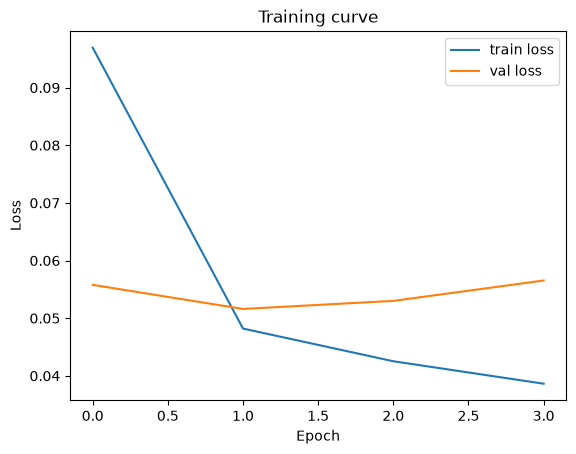

In [9]:
# 7. Plot training curves
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Training curve")
plt.savefig("training_curve.png", dpi=150)
plt.show()


In [10]:
# 8. Predict on new comments
def predict(text):
    seq = pad_sequences(tokenizer.texts_to_sequences([clean(text)]), maxlen=MAX_LEN)
    p = model.predict(seq, verbose=0)[0]
    flagged = [label for label, value in zip(LABELS, p) if value >= 0.5]
    return flagged if flagged else ["non-toxic"]

for comment in [
    "Great work, loved this!",
    "You are an idiot, shut up",
    "I will find you and hurt you",
]:
    print(f"{comment!r} -> {predict(comment)}")


'Great work, loved this!' -> ['non-toxic']
'You are an idiot, shut up' -> ['toxic', 'obscene', 'insult']
'I will find you and hurt you' -> ['toxic']
